# HA_CenterGravity: シンチレータ PMT の重心

HA モジュールは 18 台あり、それぞれ PMT 6 本を読み出します。
各 PMT の前には 8 × 8 ピクセルのシンチレータ結晶があり、PMT の 4 ch の ADC 値の比(Anger 方式)から
光った位置(重心)を求めます。SMILE_tool_box の `HA_Center_Gravity` に相当します。

- エラービットがなく、4 ch すべてが `threshold` 以上 `overflow` 以下の PMT を「有効なヒット」とする
- 重心: `x = ((a0 + a1) − (a2 + a3)) / Σa`、`y = ((a0 + a3) − (a1 + a2)) / Σa`
- 4 ch の和(生エネルギー)は、ヒットの有効・無効にかかわらず `HA_Calc` に渡す

### パラメータ

| パラメータ | 値 | 意味 |
|---|---|---|
| `threshold` | 10 | 各 ch の下限 [ADC] |
| `overflow` | 4000 | 各 ch の上限 [ADC] |

In [1]:
import sys, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、チェーンの実行スクリプト、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials" / "cache"   # チェーンの出力の置き場(チュートリアル間で共有)
CACHE.mkdir(exist_ok=True)

def vec(column):
    """RDataFrame.AsNumpy() の配列型の列 -> 2 次元の numpy 配列"""
    return np.stack([np.asarray(v) for v in column])

## 1. データのダウンロード

このチュートリアルでは 20190701 の較正データ **Per02**(線源を TPC の上方 z = −1626 mm に置いた測定)を使います。
生データ(約 17 GB)とパラメータはリポジトリに含まれていないので、研究室サーバーから手元にコピーします。

```bash
mkdir -p ~/smile2p_data
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC ~/smile2p_data/
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param ~/smile2p_data/
```

(`<user>` は自分のアカウント名)

- 途中で切れても同じコマンドで続きからコピーされます。
- `~/smile2p_data` 以外に置いた場合は、環境変数 `SMILE2P_DATA` にその場所を設定してください
  (Jupyter を起動する前に `export SMILE2P_DATA=/path/to/data`)。
- 上の形(`<置き場>/Per02_ETCC`、`<置き場>/param/20190528`)で置けば設定ファイルは書き換え不要です。
  置き方が違う場合は、設定ファイル `config/smile2p_20190701_Per02.json` の
  `ReadData.data_dir`、`TPC_Calibration.ParameterFile`、`HA_Calc.parameter_dir`、
  `HA_Calc.Modified_Parameter_Data_Dir`、`TOT_Skewness.drift_velocity_file` を自分のパスに書き換えます
  (詳しくはリポジトリ直下の README の「自分の環境に合わせて変える場所」)。
- サーバー上で実行する場合はコピーしなくても動きます(サーバー上の場所をそのまま使います)。
  ただし実行時間の大半は生データの読み込みなので、**手元のディスクにコピーした方が大幅に速く**なります
  (ネットワーク越しの場所から読むと約 10 倍遅い)。

設定ファイル `config/smile2p_20190701_Per02.json` に、データの場所(`{data_top}` はデータの置き場に置き換わる)と
各モジュールのパラメータが書かれています。データが見つかるか確認します(`MISSING` なら上のコマンドでコピー)。

In [2]:
CONFIG = "smile2p_20190701_Per02"
cfg = ec.load(CONFIG)
print("data_top:", ec.data_top())
for path in [cfg["parameters"]["ReadData"]["data_dir"], cfg["parameters"]["HA_Calc"]["parameter_dir"]]:
    print("OK     " if Path(path).is_dir() else "MISSING", path)

data_top: /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata
OK      /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC
OK      /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param/20190528


## 2. 生データツリーを作る

モジュールの出力ファイルには図(ヒストグラム)を保存せず、TTree だけを書きます。
処理の中身を確かめる図は、`ReadData → RawTreeWriter` で作る**生データツリー**(`RawTreeWriter/raw`)から描きます。
中身は `../RawTreeWriter/` を参照してください。ここでは Per02 の先頭 5000 イベントを使います。

In [3]:
# ReadData -> RawTreeWriter だけを実行して生データツリーを作る(先頭 5000 イベント、zstd 圧縮)
RAW = CACHE / "Per02_raw_5000.root"
cmd = [sys.executable, str(RUN_CHAIN), CONFIG, "-o", str(RAW), "-n", "5000", "--raw", "--compression", "505"]
print(" ".join(cmd))
if not RAW.exists():
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
    r.check_returncode()

# ボード ID の一覧(別ツリー run_info に 1 行だけ入っている)
info = ROOT.RDataFrame("RawTreeWriter/run_info", str(RAW)).AsNumpy(["anode_ids", "cathode_ids", "ha_ids"])
HA_IDS = [int(x) for x in info["ha_ids"][0]]
print("HA modules:", HA_IDS)

/usr/bin/python3 /home/onoda/ANLNext/EricaNext_try/run_script/run_chain.py smile2p_20190701_Per02 -o /home/onoda/ANLNext/EricaNext_try/tutorials/cache/Per02_raw_5000.root -n 5000 --raw --compression 505


HA modules: [1, 2, 3, 7, 8, 9, 13, 14, 15, 19, 20, 21, 25, 26, 27, 31, 32, 33]


## 3. 生データツリーの ADC から重心を求める

HA_CenterGravity と同じ計算を、生データツリーの HA の ADC に対して行います。

In [4]:
def gravity(adc, err, threshold=10, overflow=4000):
    """adc, err: [..., 24] (PMT ごとに 4 ch) -> valid[..., 6], x[..., 6], y[..., 6]"""
    a = adc.reshape(*adc.shape[:-1], 6, 4)
    e = err.reshape(*err.shape[:-1], 6, 4)
    valid = ~e.any(-1) & ((a >= threshold) & (a <= overflow)).all(-1)
    s = a.sum(-1)
    with np.errstate(invalid="ignore", divide="ignore"):
        x = ((a[..., 0] + a[..., 1]) - (a[..., 2] + a[..., 3])) / s
        y = ((a[..., 0] + a[..., 3]) - (a[..., 1] + a[..., 2])) / s
    return valid, x, y

d = (ROOT.RDataFrame("RawTreeWriter/raw", str(RAW))
     .Define("ha_err_i", "ROOT::RVecI(ha_err.begin(), ha_err.end())")   # vector<char> -> int
     .AsNumpy(["ha_adc", "ha_err_i"]))
adc = vec(d["ha_adc"]).reshape(-1, len(HA_IDS), 24).astype(float)   # [イベント, HA, ch]
err = vec(d["ha_err_i"]).reshape(-1, len(HA_IDS), 24).astype(bool)
valid, gx, gy = gravity(adc, err)
print("valid PMT hits:", valid.sum())

valid PMT hits: 5872


## 4. 重心マップ

全 HA モジュール・全 PMT(18 台 × 6 本)の重心を 1 枚に重ねて描きます。
8 × 8 のピクセル結晶が格子状に並んだ形(糸巻き型に歪んでいる)が見え、これを `HA_Calc` がピクセルに割り当てます。
PMT・モジュールごとに歪み方が少しずつ違うので、重ねると格子がぼやけます。それを PMT ごとに補正するのが `HA_Calc` の MDF 変換です。

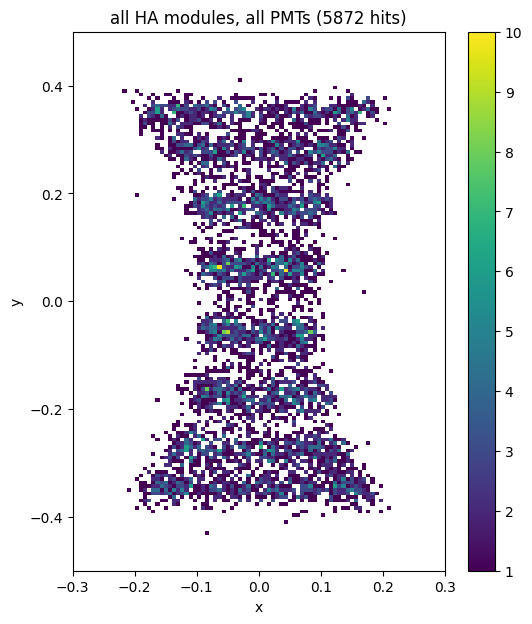

In [5]:
fig, ax = plt.subplots(figsize=(6, 7))
h = ax.hist2d(gx[valid], gy[valid], bins=[90, 150], range=[[-0.3, 0.3], [-0.5, 0.5]], cmin=1)
ax.set_title(f"all HA modules, all PMTs ({valid.sum()} hits)"); ax.set_xlabel("x"); ax.set_ylabel("y")
fig.colorbar(h[3], ax=ax); plt.show()